# AI651 Assignment 2 — Question 2

Motion or Memory?

Videos 0–7,999 train, 8,000–8,999 validation, 9,000–9,999 test. Every learned model uses Adam at 1e-3, batch 32, 30 epochs, seeds 0 and 1.

The cells below were run successfully. Full training is in `q2/train.py` and was already completed; these cells show the sanity checks and the saved results.

**Student:** Osama Atiq (25280091)

Table cells load q2 result files from figures/*.json. They do not type the table numbers in by hand. Table 1 is computed in the notebook from the transformation code.

## Table 1

In [1]:
import torch
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../q2").resolve()))
from common import M, R, Rpow, window_frames

torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7, 0, 10, 20] = 1

def bright(v):
    idx = (v == 1).nonzero()
    return tuple(int(i) for i in idx[0][[0, 2, 3]].tolist())

MRM = lambda z: M(R(M(z)))
print("a", float((M(M(x)) - x).abs().max()), torch.equal(M(M(x)), x))
print("b", float((R(R(R(R(x)))) - x).abs().max()), torch.equal(R(R(R(R(x)))), x))
print("c", float((MRM(x) - Rpow(x, -1)).abs().max()), torch.equal(MRM(x), Rpow(x, -1)))
print("d", bright(M(p)))
print("e", bright(R(p)))
v = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64).contiguous()
for name, k in (("f", 1), ("g", 2), ("h", 3)):
    X, Y = window_frames(v, 1, k)
    print(name, [int(a) for a in X[:, 0, 0, 0]], [int(a) for a in Y[:, 0, 0, 0]])


a 0.0 True
b 0.0 True
c 0.0 True
d (7, 10, 43)
e (7, 43, 10)
f [1, 2, 3, 4, 5] [6, 7, 8, 9, 10]
g [1, 3, 5, 7, 9] [11, 13, 15, 17, 19]
h [1, 4, 7, 10, 13] [16, 19]


## Figure 1

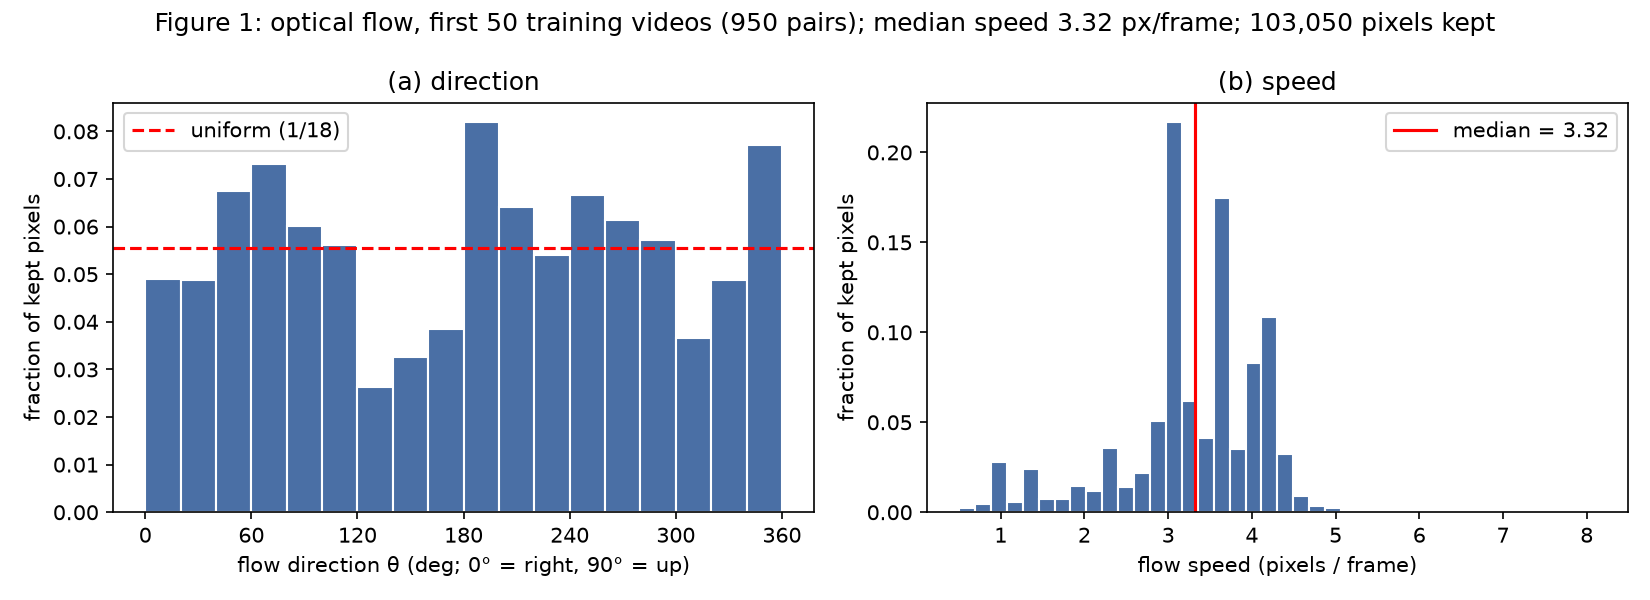

In [2]:
from IPython.display import Image, display
display(Image("figures/figure1.png"))

## Table 2 — model A, Blank, Copy-last

In [3]:
import json
from pathlib import Path
t = json.loads(Path("figures/table2.json").read_text())
a0, a1 = t["A_s0"]["mse"], t["A_s1"]["mse"]
mean = [(a0[i] + a1[i]) / 2 for i in range(5)]
print("Model A mean MSE", [round(x, 4) for x in mean])
print("E5", round(sum(mean) / 5, 4), "params", t["A_s0"]["params"])
print("Blank E5", round(t["Blank"]["E5"], 4))
print("Copy-last E5", round(t["Copy-last"]["E5"], 4))


Model A mean MSE [0.017, 0.0203, 0.0226, 0.0243, 0.026]
E5 0.022 params 480784
Blank E5 0.0426
Copy-last E5 0.0641


## Figure 2

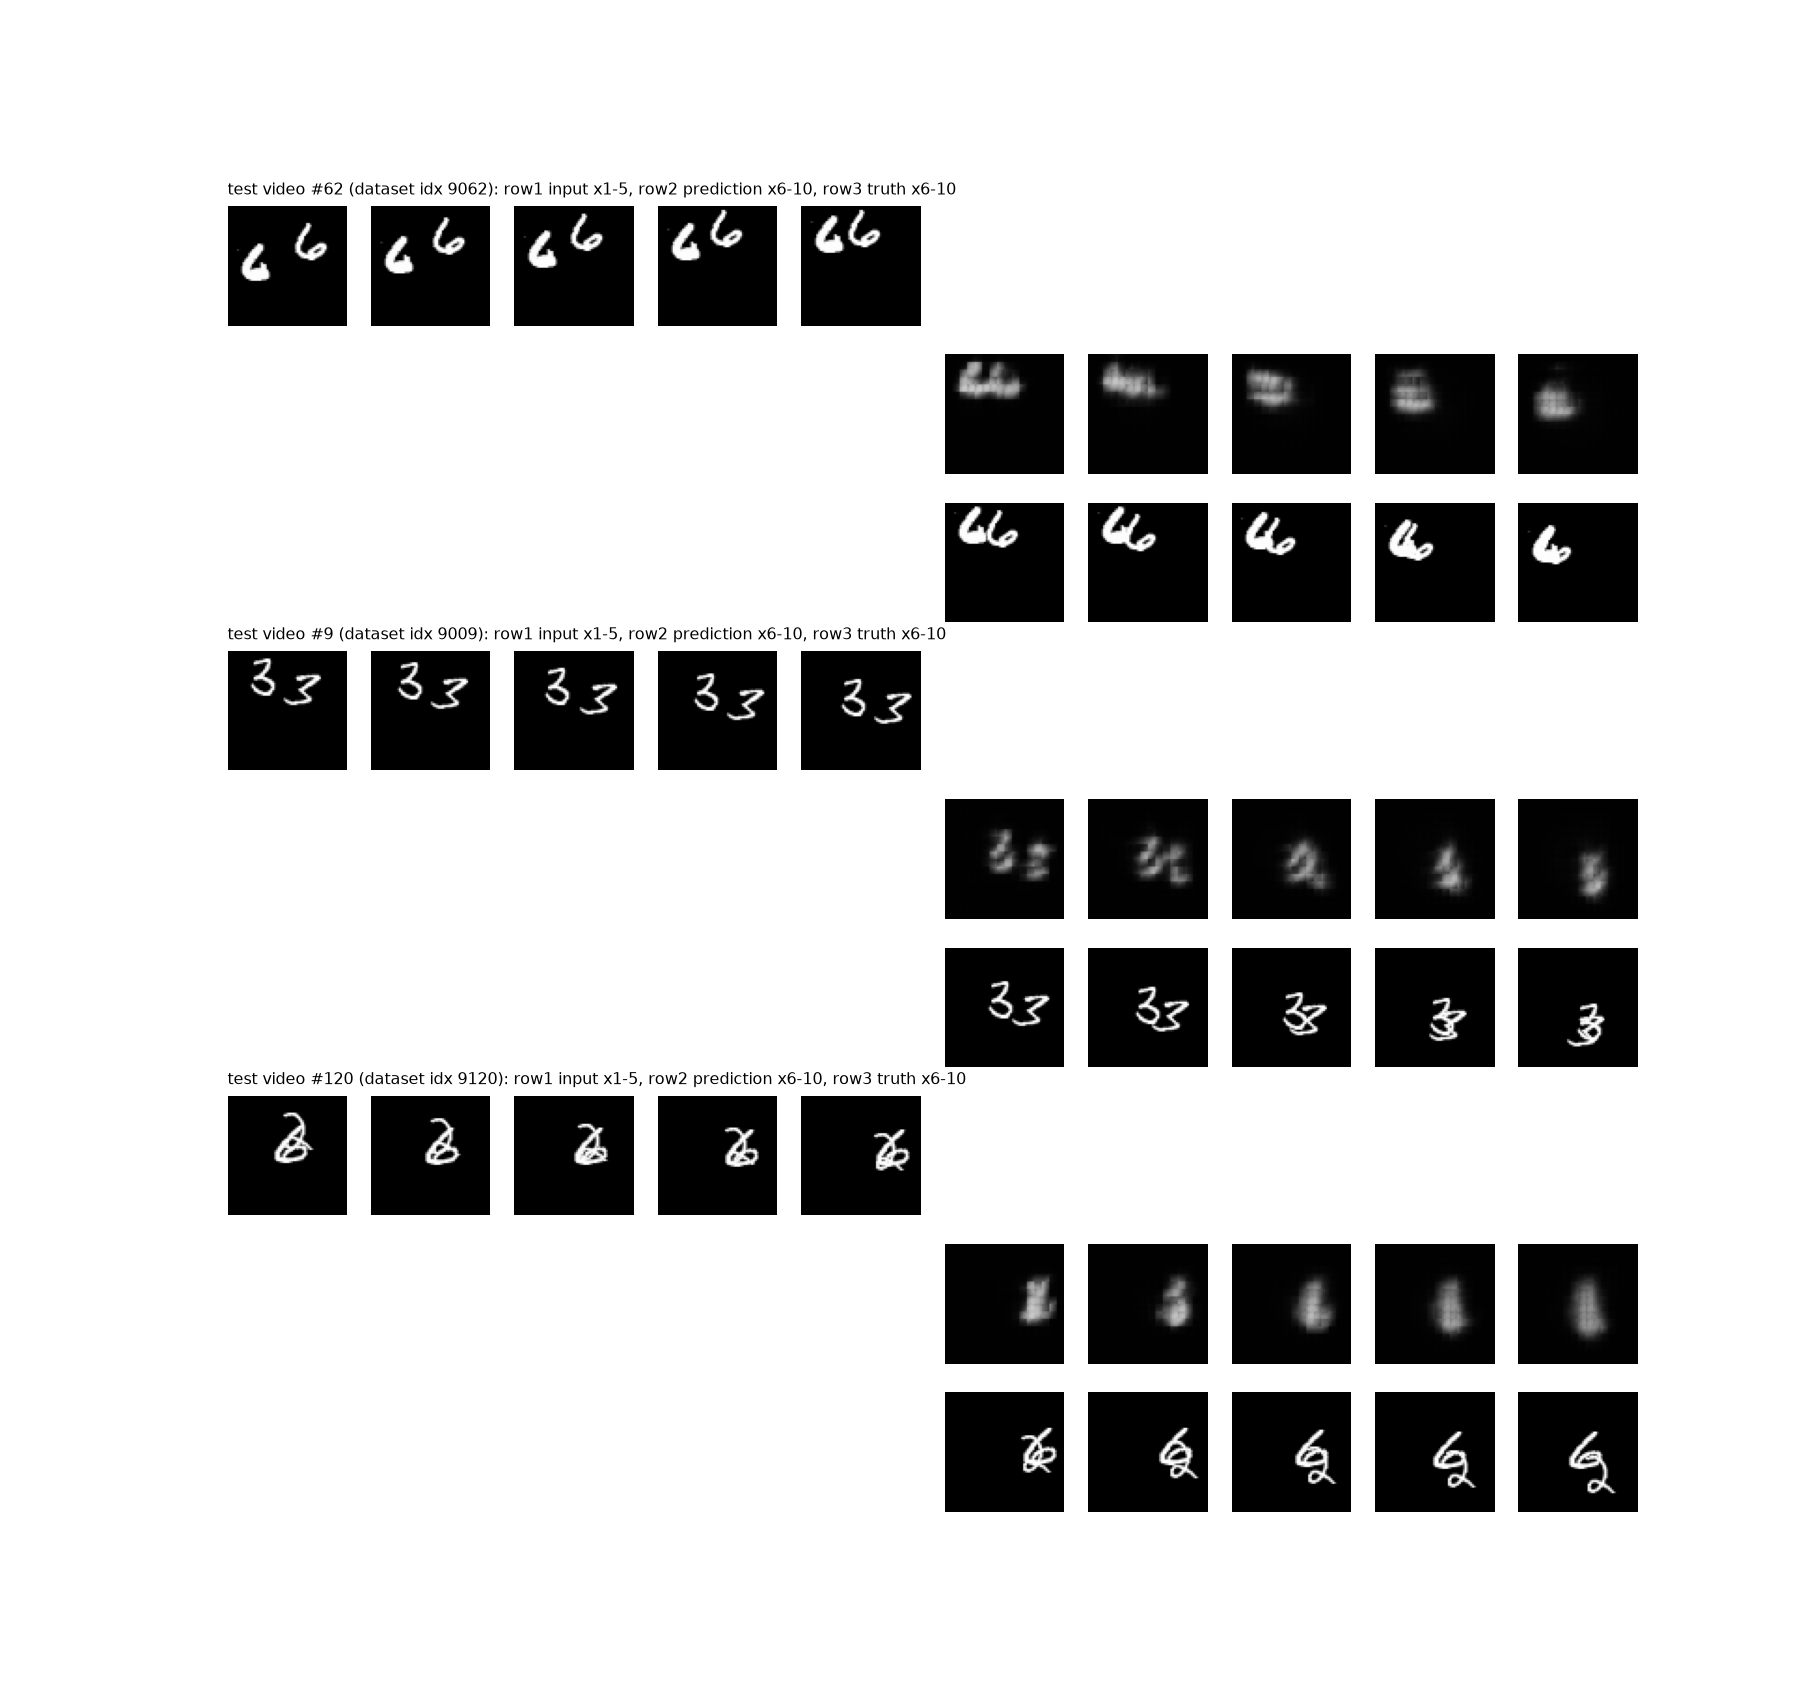

In [4]:
from IPython.display import Image, display
display(Image("figures/figure2.png"))

## Table 3 — mirror and rotation

In [5]:
import json
from pathlib import Path
t = json.loads(Path("figures/table3.json").read_text())["A"]
keys = ["E5", "CM", "EM", "CR", "ER"]
print("Model A mean", {k: round((t[k][0] + t[k][1]) / 2, 5) for k in keys})


Model A mean {'E5': 0.02205, 'CM': 0.00192, 'EM': 0.02268, 'CR': 0.00311, 'ER': 0.02383}


## Figures 3 and 4

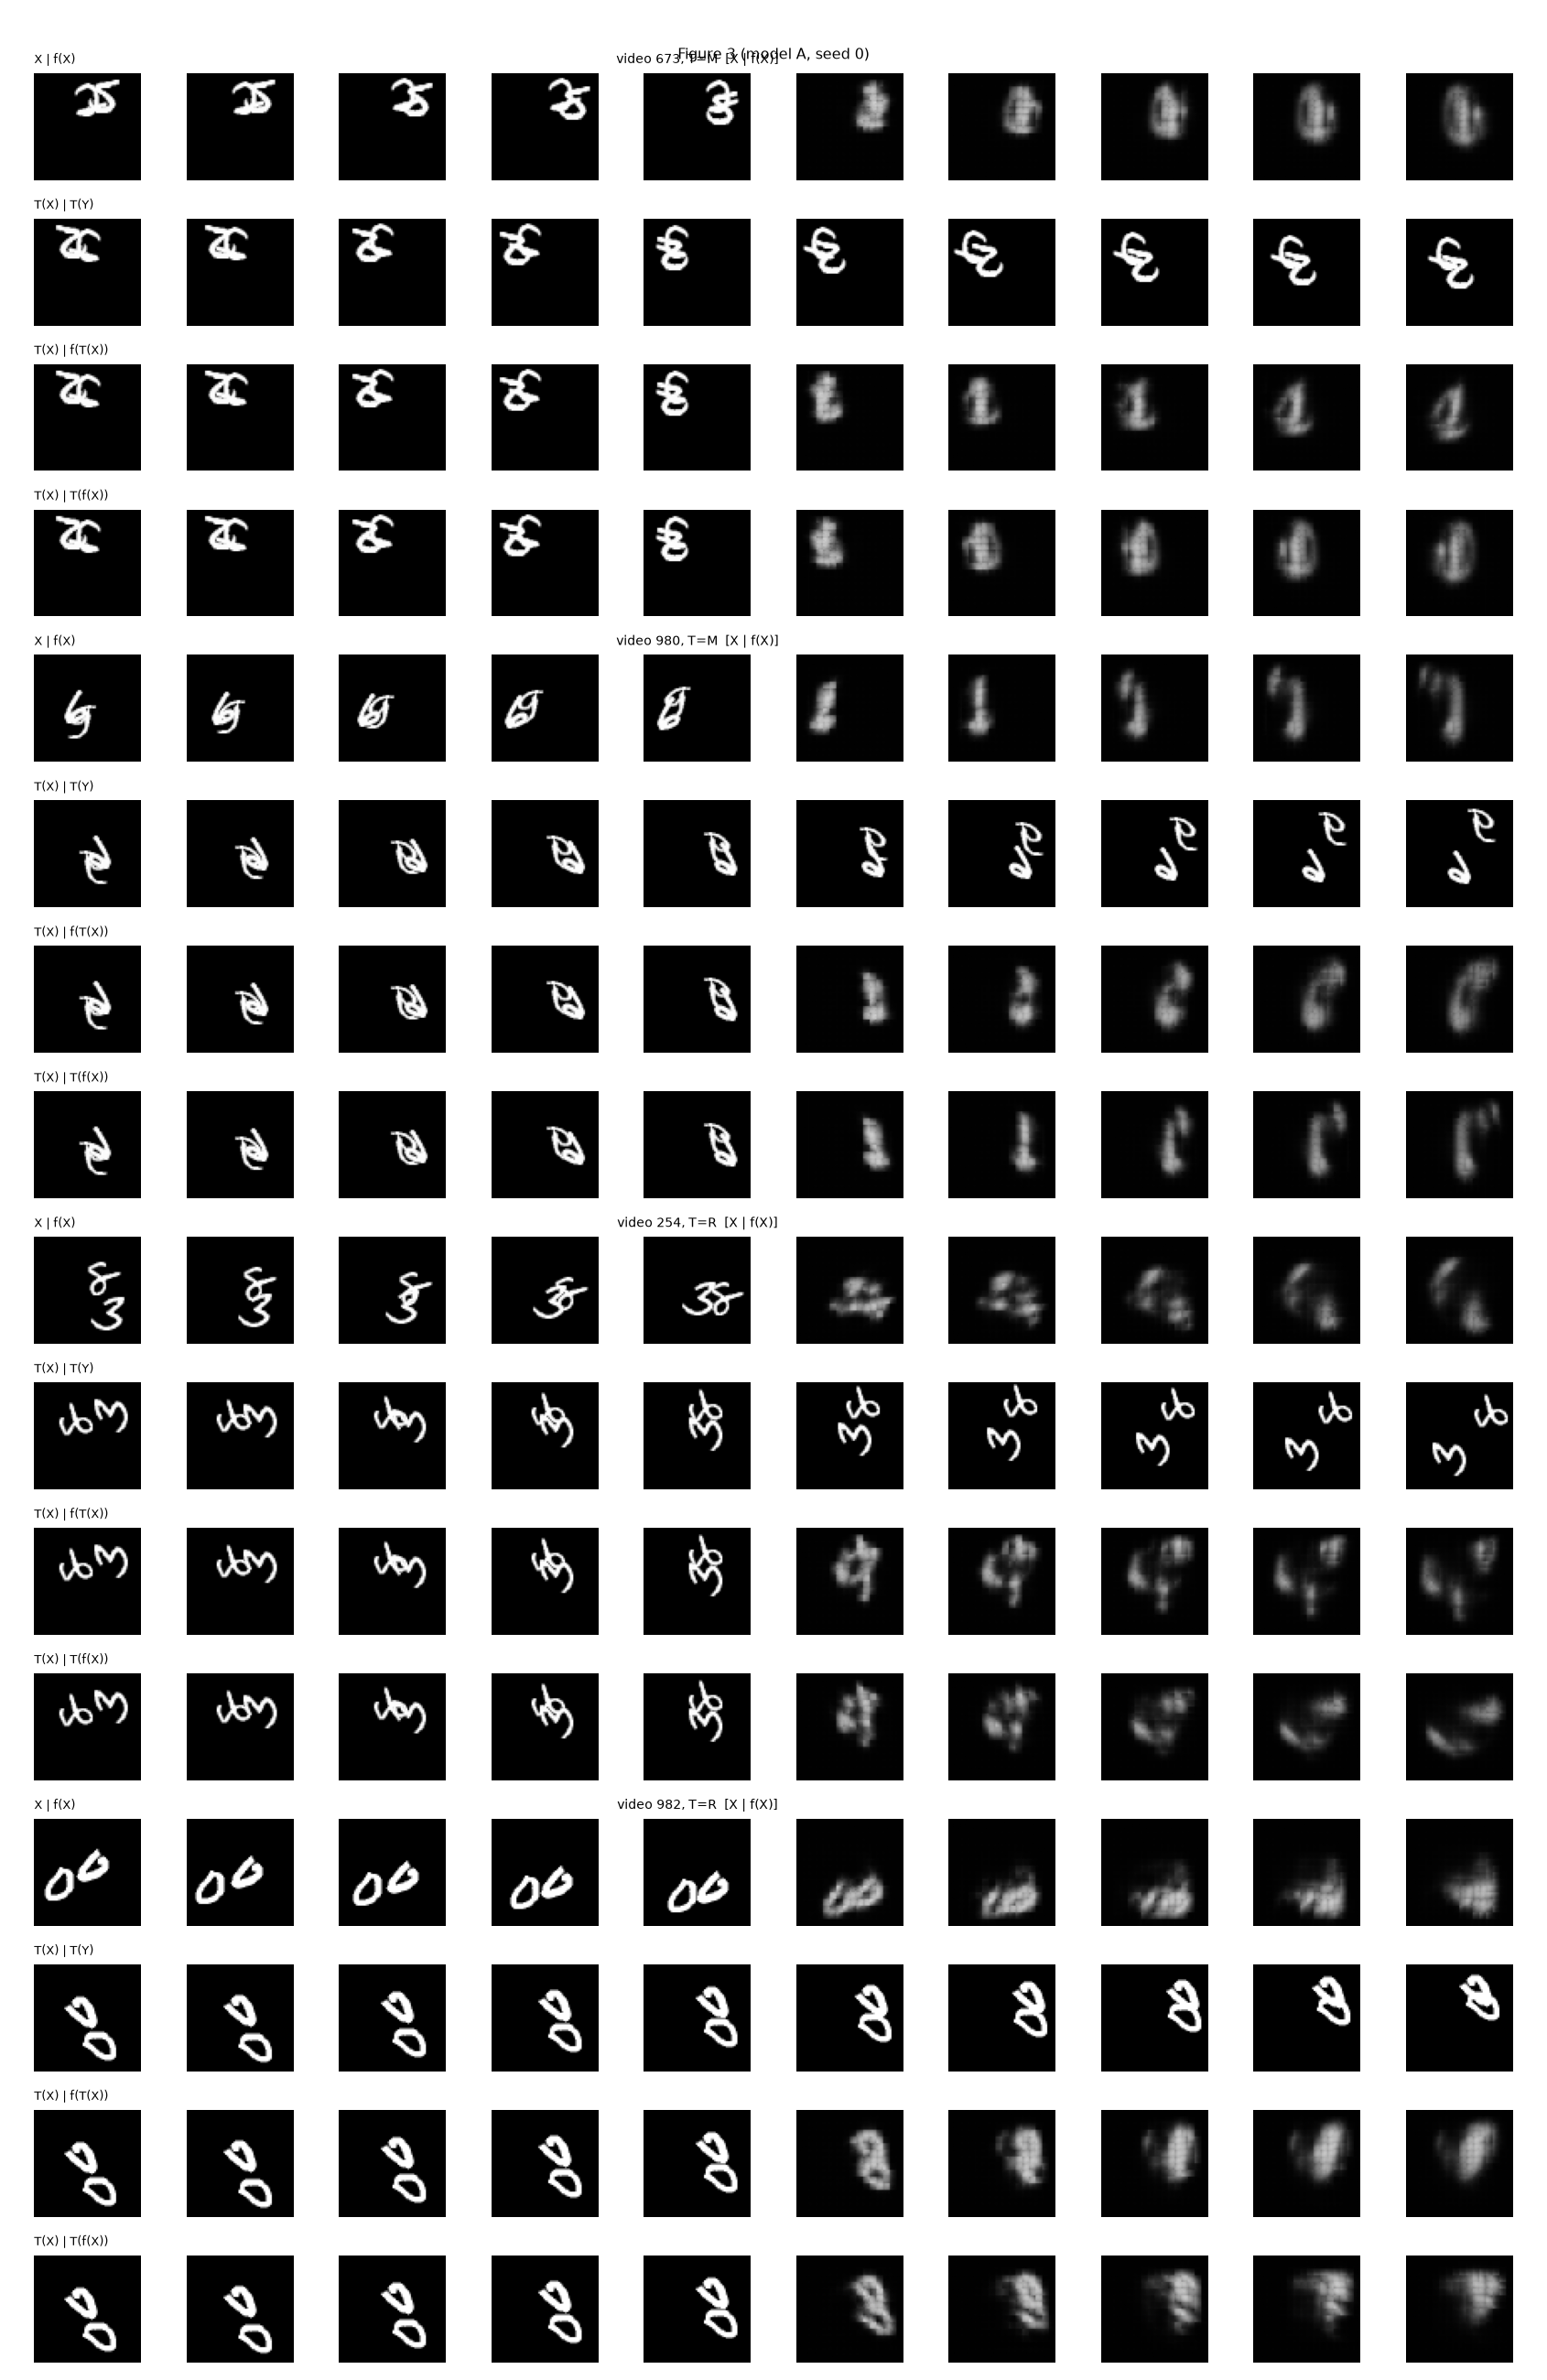

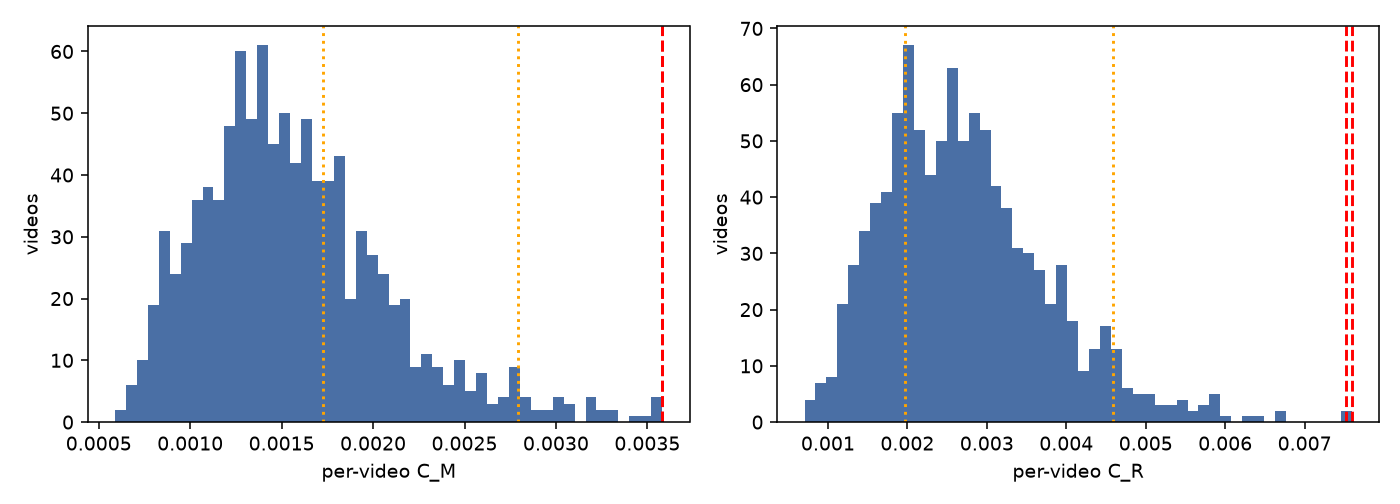

In [6]:
from IPython.display import Image, display
display(Image("figures/figure3.png"))
display(Image("figures/figure4.png"))

## Table 4 — faster motion

In [7]:
import json
from pathlib import Path
t = json.loads(Path("figures/table4.json").read_text())
for k, v in t.items():
    print(k, "mean", round((v[0] + v[1]) / 2, 4), "copy-last", round(v[2], 4))


E2_1x mean 0.0187 copy-last 0.0548
E2_2x mean 0.0448 copy-last 0.0661
E2_3x mean 0.052 copy-last 0.0703
E5_1x mean 0.022 copy-last 0.0641
E5_2x mean 0.0496 copy-last 0.0719


## Figure 5

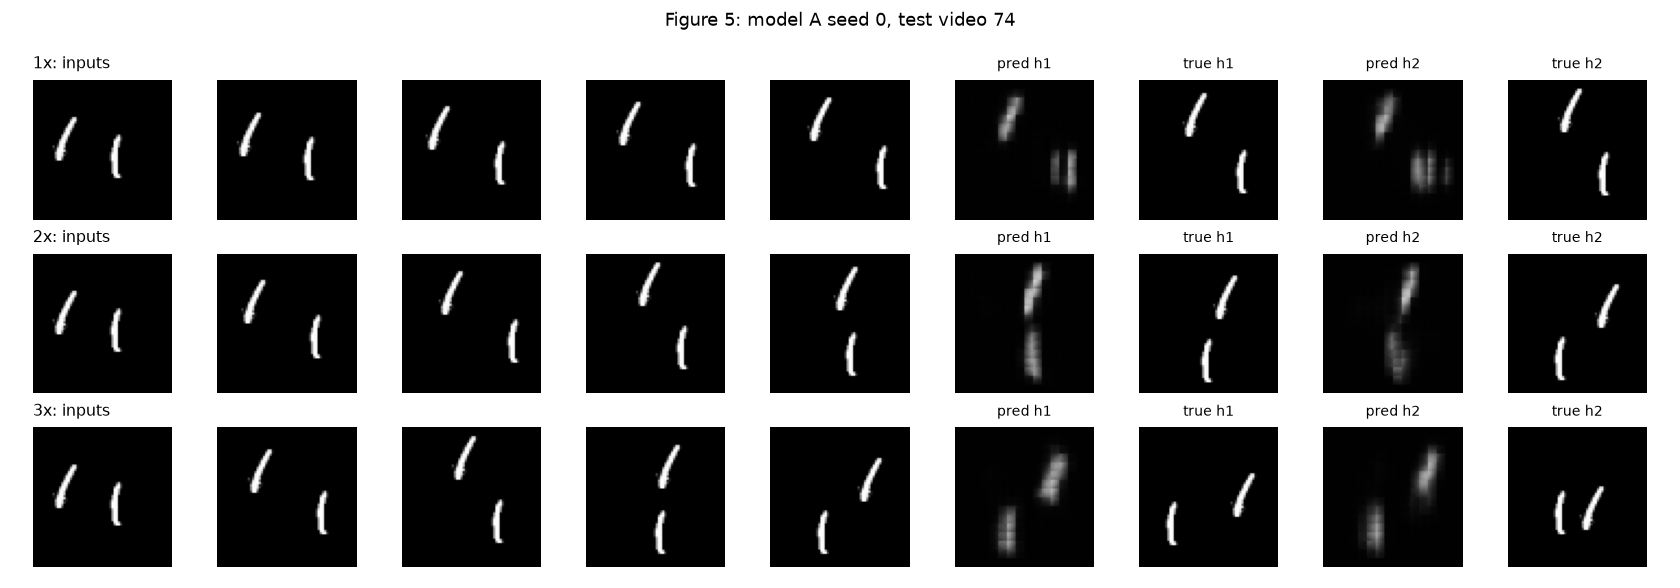

In [8]:
from IPython.display import Image, display
display(Image("figures/figure5.png"))

## Table 5 — models A, B, C, D, D+B

In [9]:
import json
from pathlib import Path
t = json.loads(Path("figures/table5.json").read_text())["table5"]
for name in ["A", "B", "C", "D", "DB"]:
    a, b = t[name + "_s0"], t[name + "_s1"]
    print(name, "E5", round((a["E5"] + b["E5"]) / 2, 4),
          "E2 1x/2x/3x", round((a["E2_1x"] + b["E2_1x"]) / 2, 4),
          round((a["E2_2x"] + b["E2_2x"]) / 2, 4),
          round((a["E2_3x"] + b["E2_3x"]) / 2, 4),
          "params", a["params"])


A E5 0.022 E2 1x/2x/3x 0.0187 0.0448 0.052 params 480784
B E5 0.0222 E2 1x/2x/3x 0.0185 0.0443 0.051 params 480784
C E5 0.0269 E2 1x/2x/3x 0.0234 0.0289 0.0335 params 480784
D E5 0.0272 E2 1x/2x/3x 0.0243 0.0284 0.0321 params 572560
DB E5 0.0274 E2 1x/2x/3x 0.0244 0.0286 0.0322 params 572560


## Table 6 and Figure 6 — final symmetrised model

In [10]:
import json
from pathlib import Path
t = json.loads(Path("figures/table6.json").read_text())["table6"]
for name in ["B", "D", "DB"]:
    a, b = t["sym_" + name + "_s0"], t["sym_" + name + "_s1"]
    print("sym", name, "E5", round((a["E5"] + b["E5"]) / 2, 4),
          "CM", (a["CM"] + b["CM"]) / 2, "CR", (a["CR"] + b["CR"]) / 2)


sym B E5 0.0216 CM 8.383596607466613e-17 CR 6.751479923393334e-17
sym D E5 0.0271 CM 5.049842679301913e-17 CR 3.894310571926368e-17
sym DB E5 0.027 CM 5.72586563020598e-17 CR 4.462775393216288e-17


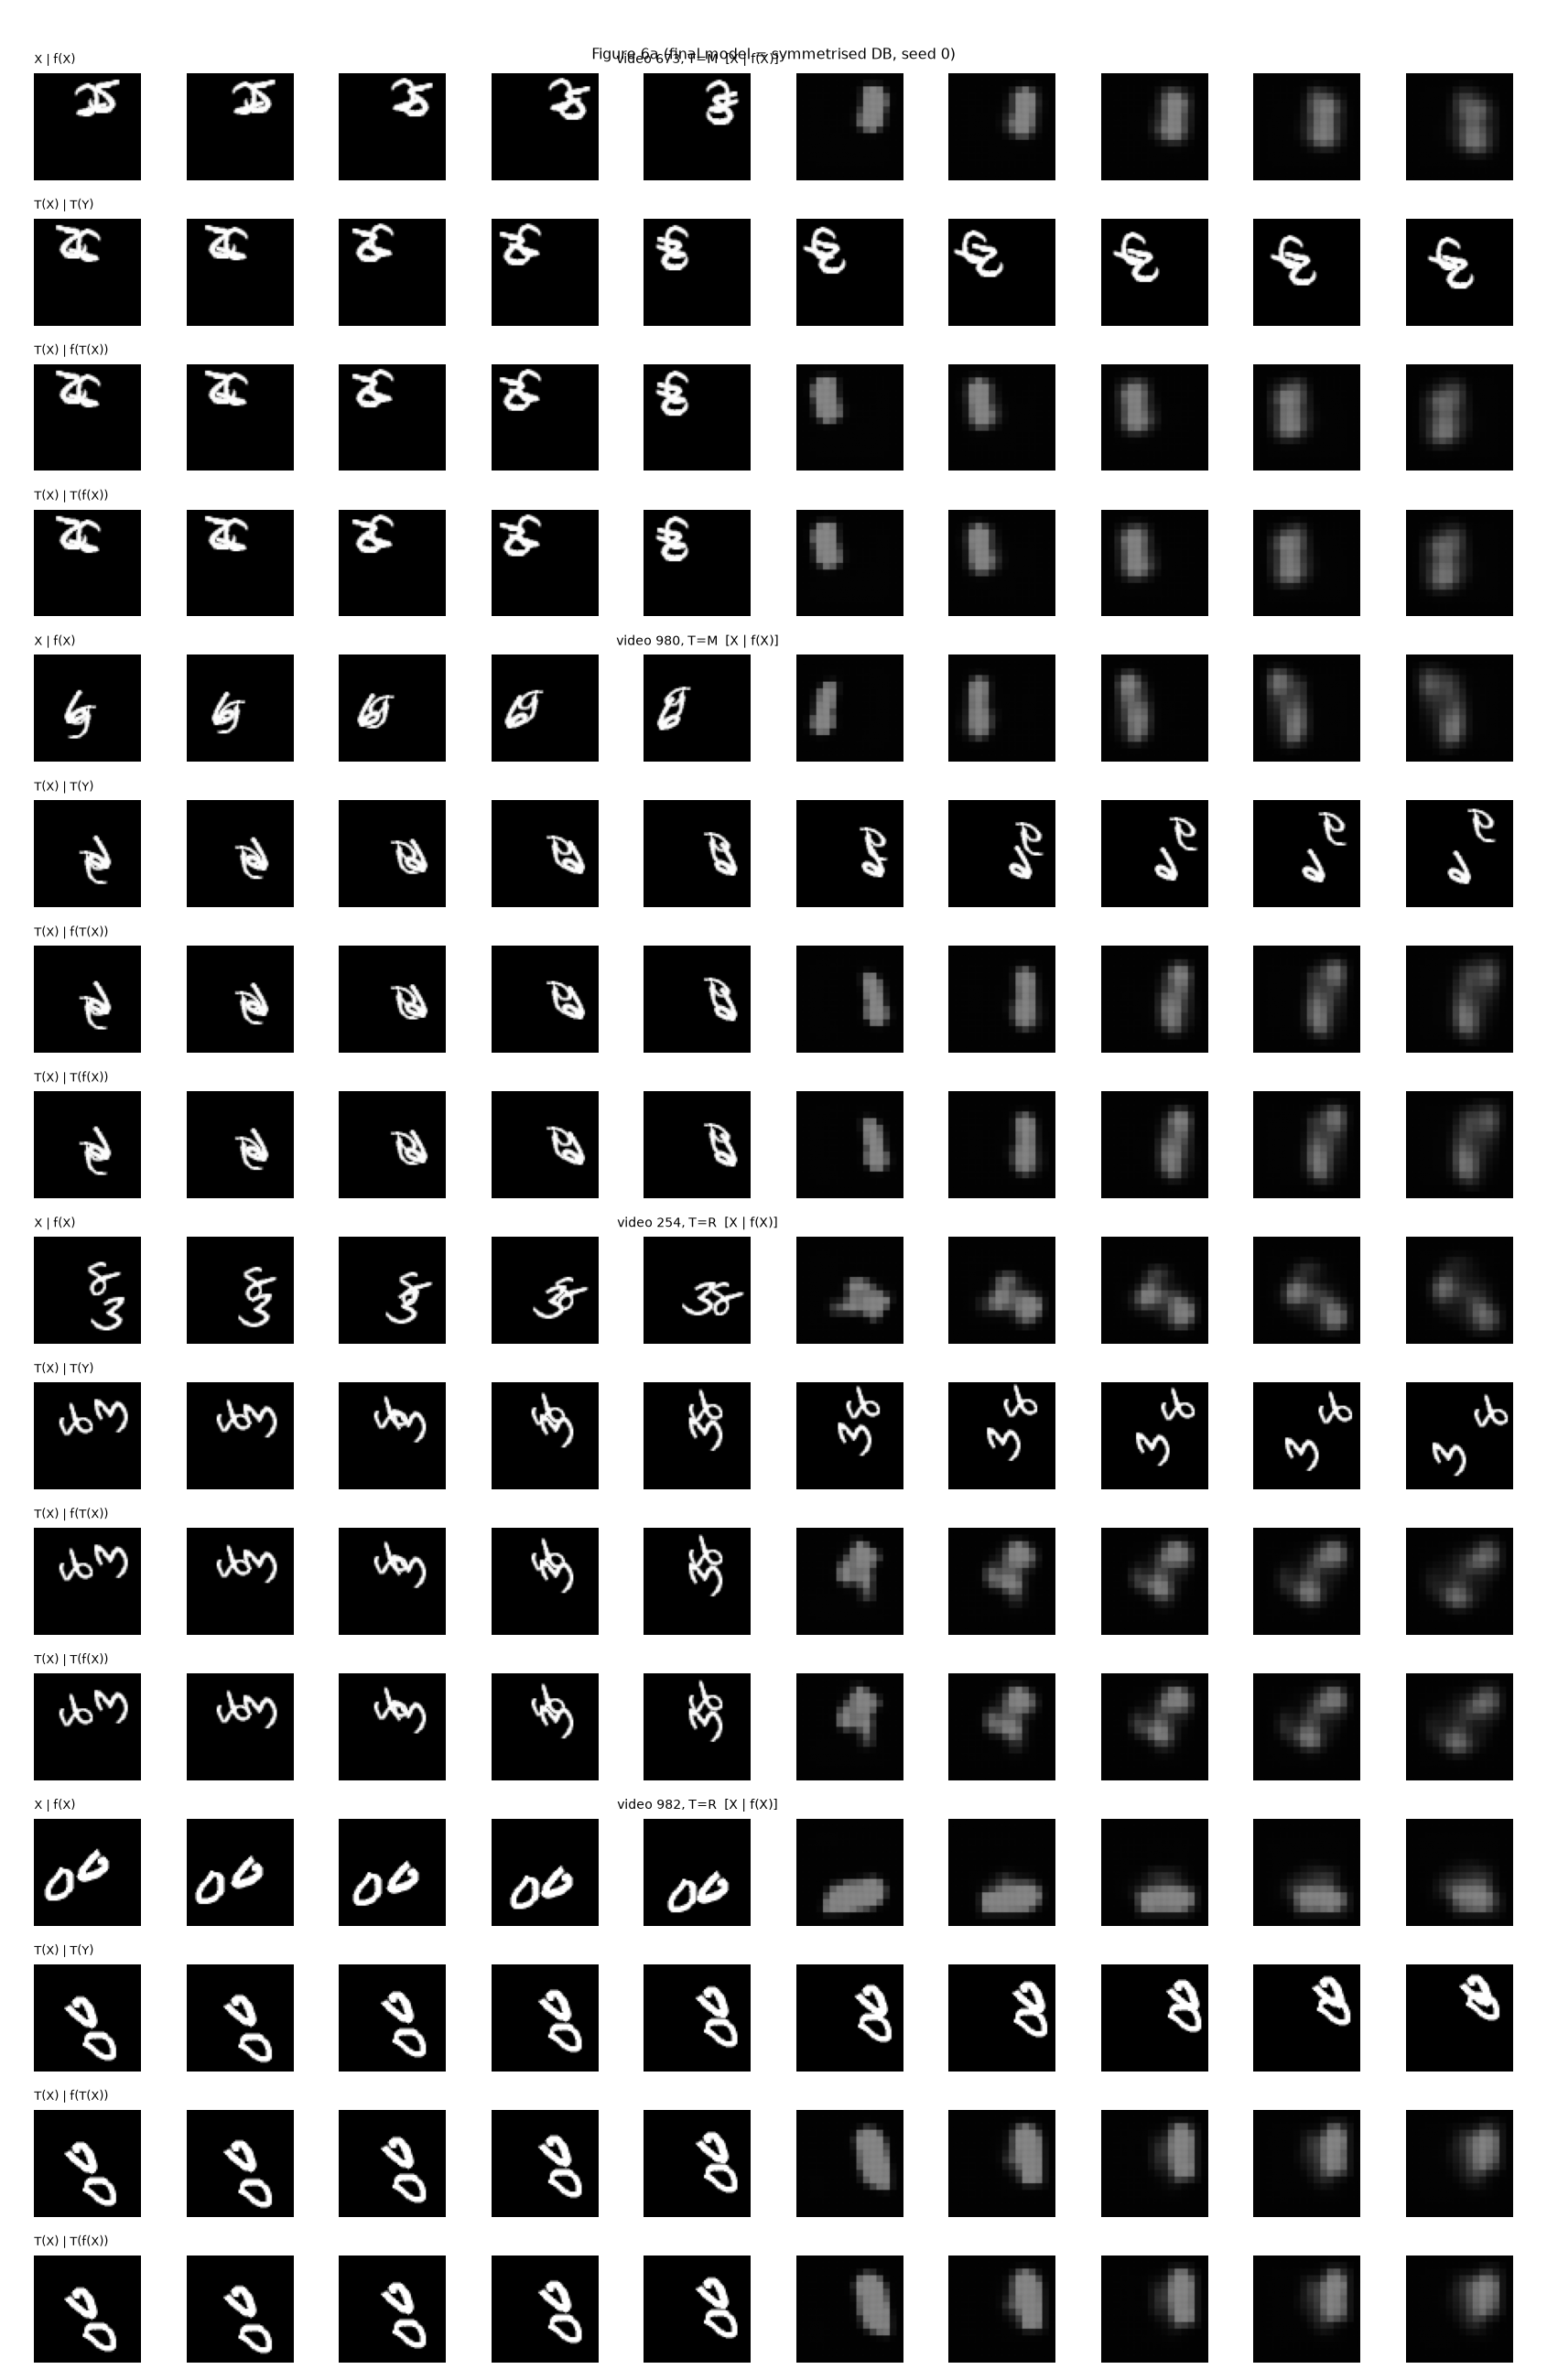

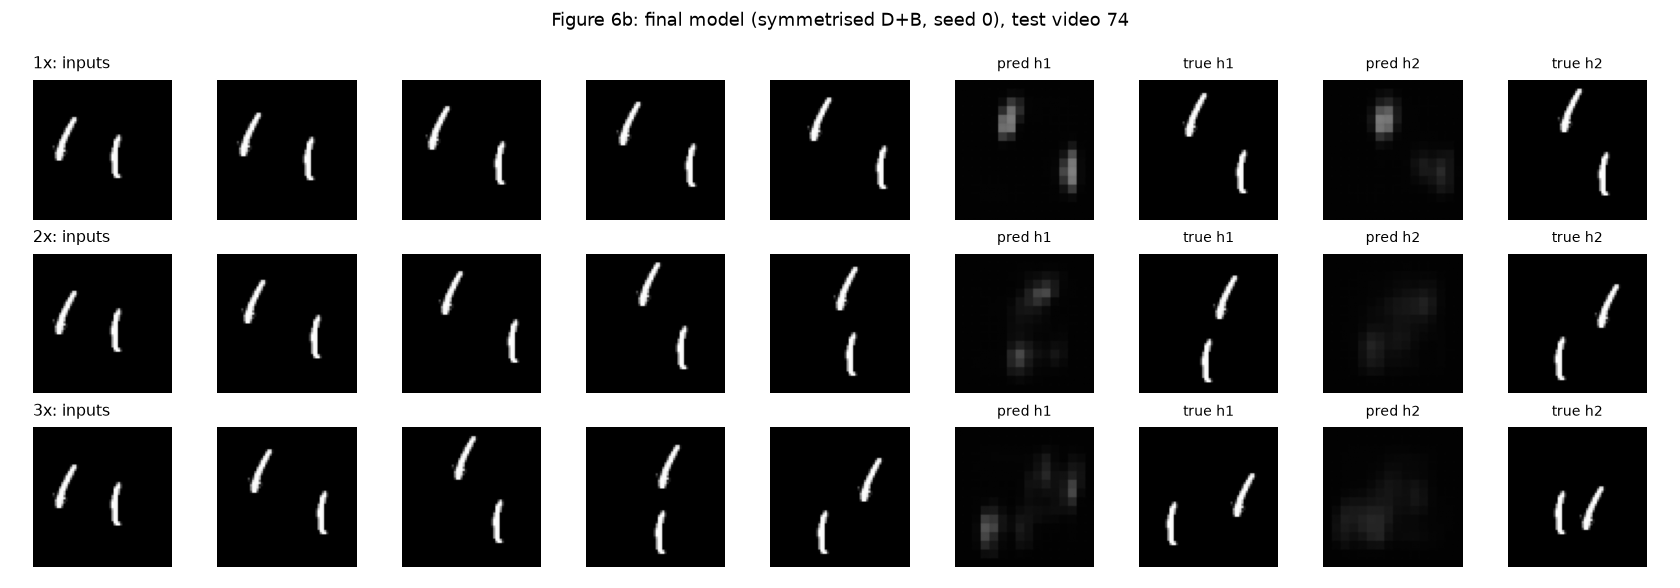

In [11]:
from IPython.display import Image, display
display(Image("figures/figure6a.png"))
display(Image("figures/figure6b.png"))

GIFs for Figures 3 and 6a are in `q2/gifs_A/` and `q2/gifs_final/`.